# Understanding Multicollinearity: A Beginner's Guide

---

## 1. What is Multicollinearity?

Imagine you are attending a live concert where two vocalists are singing the exact same lyrics, into identical microphones, with identical pitch and volume, at the exact same fraction of a second.

The performance sounds great to the audience, but if someone asks you:
> *"Exactly how much of the vocal power came from Singer A, and how much came from Singer B?"*

You cannot answer with certainty. Both singers are doing the exact same thing at the exact same time.

**This is what multicollinearity is in Machine Learning:**

* **"Collinear"** means two variables move in a straight line together.
* **"Multi-collinear"** means two or more input features in your dataset are carrying nearly the same information and moving together in tandem.

### Why Does It Occur in a Dataset?
Multicollinearity occurs naturally in real-world data collection when:
1. **Features measure different aspects of the same physical thing** (e.g., house square footage, total number of rooms, and number of bedrooms).
2. **Duplicate or redundant metrics are recorded** (e.g., a person's height recorded in centimeters and their height recorded in inches).
3. **Engineered features overlap heavily** (e.g., creating both total purchase amount and average item cost when cart size is almost constant).

---

## 2. A Simple Example: House Price Prediction

Let's look at a simple scenario where we want to predict **House Price** using three features:
* **House Size (sq ft)**
* **Total Rooms**
* **Bedrooms**

Here is a small example dataset:

| House ID | House Size (sq ft) | Total Rooms | Bedrooms | House Price (USD in thousands) |
| :--- | :---: | :---: | :---: | :---: |
| 1 | 1,100 | 4 | 2 | 210k |
| 2 | 1,450 | 5 | 2 | 250k |
| 3 | 1,800 | 6 | 3 | 300k |
| 4 | 2,100 | 6 | 3 | 340k |
| 5 | 2,550 | 8 | 4 | 410k |
| 6 | 2,900 | 9 | 4 | 460k |
| 7 | 3,200 | 9 | 5 | 490k |
| 8 | 3,600 | 11 | 5 | 560k |

### Why This Creates Multicollinearity
* When a house gets bigger (**House Size** increases), the builder naturally creates more **Total Rooms**.
* When there are more **Total Rooms**, there are almost always more **Bedrooms**.

Because all three features grow in lockstep, each feature is "shouting" the exact same piece of information: **"This is a large house!"**

---

## 3. Why is Multicollinearity a Problem?

If multiple features tell the same story, why should we care?

### Problem 1: Unstable and Confusing Coefficients
In linear regression, the model tries to assign an importance weight (coefficient) to each feature, answering:
> *"If I increase this feature by 1 unit while holding everything else constant, how much does the price change?"*

When features are glued together, the model cannot realistically "hold one constant while changing the other." As a result:
* The model's coefficients become wild and unpredictable.
* You might see **bizarre signs** — for example, the model might assign a **negative coefficient to Bedrooms** (suggesting that adding a bedroom makes a house cheaper!), just to balance out a large positive coefficient on House Size.

### Problem 2: High Uncertainty (Wide Confidence Intervals)
The model becomes unsure of which feature is actually driving the target. Standard errors become inflated, meaning you cannot trust the p-values or feature importance rankings.

### Problem 3: Fragile Models
Small tweaks to your training data (like adding or removing just a few houses) can cause coefficients to swing from positive to negative, making the model untrustworthy for business explanations.

---

## 4. How to Detect Multicollinearity

There are two primary, beginner-friendly tools to detect multicollinearity:

```
Detection Method 1: Correlation Matrix (Heatmap)
   ↳ Best for checking pairwise relationships between two features at a time.

Detection Method 2: Variance Inflation Factor (VIF)
   ↳ Best for checking if a feature is redundant with ANY combination of other features.
```

### Method 1: Correlation Matrix
A correlation matrix checks how closely pairs of variables move together:
* **Value near +1.0:** The two features increase together almost perfectly.
* **Value near -1.0:** When one increases, the other decreases almost perfectly.
* **Value near 0.0:** There is no linear relationship between them.

**Rule of Thumb:** A correlation above **0.80** or **0.85** between two input features usually indicates potential multicollinearity.

#### Python Example: Correlation Heatmap

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


Correlation Matrix:
                 House_Size_sqft  Total_Rooms  Bedrooms  House_Age_years
House_Size_sqft             1.00         0.99      0.98            -0.49
Total_Rooms                 0.99         1.00      0.96            -0.44
Bedrooms                    0.98         0.96      1.00            -0.47
House_Age_years            -0.49        -0.44     -0.47             1.00


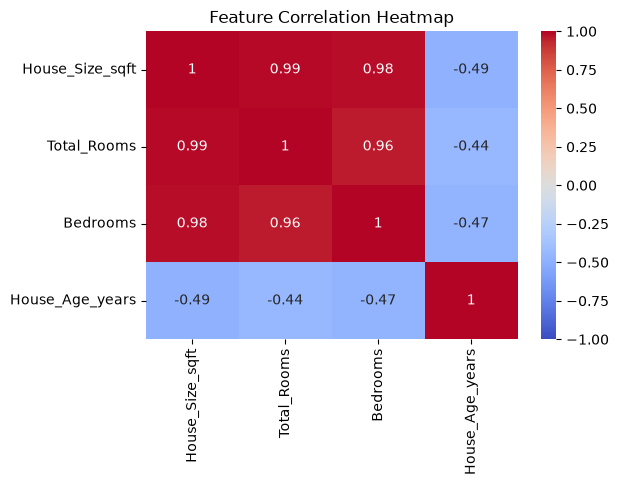

In [2]:

# 1. Create the example housing data
data = {
    'House_Size_sqft': [1100, 1450, 1800, 2100, 2550, 2900, 3200, 3600],
    'Total_Rooms':     [   4,    5,    6,    6,    8,    9,    9,   11],
    'Bedrooms':        [   2,    2,    3,    3,    4,    4,    5,    5],
    'House_Age_years': [  15,    5,   20,    8,    3,   12,    2,    6],
    'House_Price':     [ 210,  250,  300,  340,  410,  460,  490,  560]
}
df = pd.DataFrame(data)

# 2. Select input features only (do not include the target 'House_Price')
features = df[['House_Size_sqft', 'Total_Rooms', 'Bedrooms', 'House_Age_years']]

# 3. Compute pairwise correlation matrix
corr_matrix = features.corr().round(2)
print("Correlation Matrix:")
print(corr_matrix)

# 4. Plot visual heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Feature Correlation Heatmap")
plt.show()

---

### Method 2: Variance Inflation Factor (VIF)
While correlation checks only two features at a time, **VIF** tests whether a feature can be predicted by a combination of *all* other features.

Think of VIF as a **"Redundancy Score"**:
* **VIF = 1:** Completely independent (zero redundancy).
* **VIF between 1 and 5:** Low to moderate correlation. Usually safe and acceptable.
* **VIF between 5 and 10:** High correlation. Worth investigating.
* **VIF > 10:** Severe multicollinearity. One or more features are almost entirely redundant and should be addressed.

#### Python Example: Calculating VIF

In [4]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Select the input feature matrix
X = df[['House_Size_sqft', 'Total_Rooms', 'Bedrooms', 'House_Age_years']]

# 2. Calculate VIF for each feature
vif_report = pd.DataFrame()
vif_report['Feature'] = X.columns
vif_report['VIF_Score'] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]

# 3. Display sorted VIF scores
print(vif_report.sort_values(by='VIF_Score', ascending=False).round(2))

           Feature  VIF_Score
0  House_Size_sqft      96.36
1      Total_Rooms      50.52
2         Bedrooms      23.39
3  House_Age_years       1.56


**Output Interpretation:**
```
           Feature  VIF_Score
0  House_Size_sqft      96.36   <-- Severe redundancy!
1      Total_Rooms      50.52   <-- Severe redundancy!
2         Bedrooms      23.39   <-- Severe redundancy!
3  House_Age_years       1.56   <-- Safe and independent
```
The VIF scores clearly warn us that `House_Size_sqft`, `Total_Rooms`, and `Bedrooms` are heavily overlapping. Meanwhile, `House_Age_years` is around 1.56, meaning it provides clean, independent information.

---

## 5. How to Solve Multicollinearity

Here are 5 practical ways to handle multicollinearity, ranked from simplest to most advanced:

| Method | What It Does | When To Use | Model Impact |
| :--- | :--- | :--- | :--- |
| **1. Drop Redundant Features** | Remove one of the highly correlated columns | Two features measure nearly identical concepts | Simpler, cleaner model with stable coefficients |
| **2. Combine Features** | Merge related features into a meaningful metric | Both variables contain useful nuance | Preserves information without duplication |
| **3. Feature Selection** | Let an algorithm pick the most predictive subset | You have dozens of overlapping features | Automates selection of the strongest predictors |
| **4. PCA (Dimensionality Reduction)** | Compress correlated features into new, uncorrelated components | Interpretability is secondary to prediction | Removes all collinearity, but creates abstract features |
| **5. Regularization (Ridge / Lasso)** | Penalize large or unstable coefficients | You want to keep all features without manual dropping | Ridge stabilizes weights; Lasso zeroes out redundancies |

---

### Solution 1: Remove One of the Highly Correlated Features
* **When to use:** When two features tell virtually the same story (e.g., `Total_Rooms` vs. `House_Size_sqft`).
* **Example:** Keep `House_Size_sqft` because it is continuous and granular; drop `Total_Rooms`.
* **Expected Effect:** VIF scores drop dramatically toward 1.0, and remaining coefficients become stable and easy to explain.

### Solution 2: Combine Related Features
* **When to use:** When both variables contain slight unique value that you don't want to throw away.
* **Example:** Instead of keeping both `Total_Rooms` and `Bedrooms`, create a new ratio or difference:

In [ ]:
  # Creates a new non-collinear feature: Living area per room
df['Avg_Room_Size'] = df['House_Size_sqft'] / df['Total_Rooms']

* **Expected Effect:** Replaces two overlapping features with one distinct, domain-meaningful feature.

### Solution 3: Feature Selection (e.g., Sequential Feature Selection or RFE)
* **When to use:** When your dataset has dozens of columns and manual inspection of pairs is too tedious.
* **Example:** Use Scikit-Learn's `SelectKBest` or `RFE` to retain only the top non-redundant predictors based on target correlation.
* **Expected Effect:** Automatically prunes redundant columns that offer diminishing marginal predictive power.

### Solution 4: Principal Component Analysis (PCA)
* **When to use:** When you have many correlated features and you prioritize prediction accuracy over being able to explain individual column weights.
* **Example:** PCA blends `House_Size_sqft`, `Total_Rooms`, and `Bedrooms` into 1 or 2 new composite variables called "Principal Components" that are guaranteed to have zero correlation with each other.
* **Expected Effect:** Completely eliminates multicollinearity, but the new features (e.g., `PC1`, `PC2`) cannot be easily explained to non-technical stakeholders.

### Solution 5: Regularization (Ridge and Lasso)
* **When to use:** When you want to keep all features in the model without manually choosing which ones to drop.
* **Example:**
  * **Ridge (L2 Penalty):** Shrinks coefficients smoothly so they cannot blow up to extreme positive or negative numbers.
  * **Lasso (L1 Penalty):** Shrinks the coefficient of redundant features all the way to **zero**, acting like automatic feature removal.
* **Expected Effect:** Prevents coefficient explosion and produces stable, well-generalized predictions.

---

## 6. Before-and-After Example

Let's walk through an end-to-end Python demonstration showing how multicollinearity misleads linear regression and how resolving it fixes the issue.

In [5]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor

# -------------------------------------------------------------
# STEP 1: Define Dataset
# -------------------------------------------------------------
data = {
    'House_Size_sqft': [1100, 1450, 1800, 2100, 2550, 2900, 3200, 3600],
    'Total_Rooms':     [   4,    5,    6,    6,    8,    9,    9,   11],
    'Bedrooms':        [   2,    2,    3,    3,    4,    4,    5,    5],
    'House_Age_years': [  15,    5,   20,    8,    3,   12,    2,    6],
    'House_Price':     [ 210,  250,  300,  340,  410,  460,  490,  560]
}
df = pd.DataFrame(data)
y = df['House_Price']

# -------------------------------------------------------------
# STEP 2: Train Model WITH Multicollinearity (Before)
# -------------------------------------------------------------
X_before = df[['House_Size_sqft', 'Total_Rooms', 'Bedrooms', 'House_Age_years']]

model_before = LinearRegression()
model_before.fit(X_before, y)

print("=== BEFORE SOLVING MULTICOLLINEARITY ===")
for feature, coef in zip(X_before.columns, model_before.coef_):
    print(f"{feature:18s}: {coef:10.4f}")

# Look at the Bedrooms coefficient:
# It comes out NEGATIVE (-1.1466)! 
# The model claims that adding a bedroom decreases the house price,
# which defies common sense. That is multicollinearity in action.

# -------------------------------------------------------------
# STEP 3: Apply Solution (Drop Redundant Features)
# We keep House_Size_sqft (broad capacity) and House_Age_years (quality/age),
# and drop Total_Rooms and Bedrooms.
# -------------------------------------------------------------
X_after = df[['House_Size_sqft', 'House_Age_years']]

model_after = LinearRegression()
model_after.fit(X_after, y)

print("\n=== AFTER SOLVING MULTICOLLINEARITY ===")
for feature, coef in zip(X_after.columns, model_after.coef_):
    print(f"{feature:18s}: {coef:10.4f}")

# -------------------------------------------------------------
# STEP 4: Compare VIF Scores Before vs. After
# -------------------------------------------------------------
vif_after = pd.DataFrame({
    'Feature': X_after.columns,
    'VIF_Score': [variance_inflation_factor(X_after.values, i) for i in range(len(X_after.columns))]
})

print("\nVIF Scores After Pruning:")
print(vif_after.round(2))

=== BEFORE SOLVING MULTICOLLINEARITY ===
House_Size_sqft   :     0.1152
Total_Rooms       :     9.9835
Bedrooms          :    -1.1466
House_Age_years   :     0.0736

=== AFTER SOLVING MULTICOLLINEARITY ===
House_Size_sqft   :     0.1413
House_Age_years   :     0.3106

VIF Scores After Pruning:
           Feature  VIF_Score
0  House_Size_sqft       1.32
1  House_Age_years       1.32


### Summary of What Changed:
* **Before:** `Bedrooms` had an nonsensical negative coefficient (`-1.15`), and VIF scores were sky-high (up to `96.36`).
* **After:** Both remaining features have clean, positive, logical coefficients (`House_Size_sqft: +0.1413`, `House_Age_years: +0.3106`), and their VIF scores dropped safely to **1.32**.

---

## 7. An Important Distinction: Prediction vs. Interpretation

A very common point of confusion for beginners is:
> *"If my model has multicollinearity, does that mean its predictions are broken?"*

**The short answer: Not necessarily!**

* **If your primary goal is pure prediction:**
  Multicollinearity does not usually ruin the overall accuracy (such as R-squared or Mean Squared Error), provided that future unseen data follows the exact same correlation pattern as the training data.
* **If your primary goal is interpretation or causal understanding:**
  Multicollinearity is a serious roadblock. If a real-estate client asks: *"How much extra value does adding one bedroom add to my property?"*, a model with multicollinearity cannot give an honest or reliable answer.

```
       Prediction Focus                     Interpretation Focus
   (e.g., Kaggle, pure forecast)         (e.g., Business Strategy, Healthcare)
                 │                                         │
                 ▼                                         ▼
   Multicollinearity is often safe          Multicollinearity MUST be fixed
      to leave alone or manage                so coefficients reflect true
        with Ridge/Tree models.                   individual effects.
```

---

## 8. Key Takeaways Checklist

* [ ] **What it is:** Two or more input features providing redundant, overlapping information.
* [ ] **Why it occurs:** Measuring different aspects of the same underlying physical attribute.
* [ ] **The real symptom:** Unstable coefficients, flipped signs (positive to negative), and inflated standard errors.
* [ ] **How to spot it:** Correlation matrix heatmap (greater than 0.80) and VIF scores (greater than 5 or 10).
* [ ] **The fastest fix:** Drop the redundant column or combine features into a composite metric.
* [ ] **The golden rule:** Multicollinearity hurts **explanation and interpretability**, but does not necessarily destroy **pure prediction**.
